# IMDb data analysis in Python

**Research question:** Is it possible to tell from average ratings and number of votes when *The Simpsons* stopped being (that) good?

This notebook uses IMDb's public datasets to explore that question. The steps are:

1. Load four IMDb tables (alternative titles, basic title information, ratings and episode information).
2. Merge them into one table with a single row for each episode of *The Simpsons*.
3. Look at the highest and lowest rated episodes.
4. Plot ratings, number of votes and season number to look for patterns.
5. Run a k-means cluster analysis to group the episodes by how similar they are in votes, rating and season.

In [ ]:
# Install the libraries
#%pip install pandas matplotlib

# pandas is used for loading, filtering and merging the tables
import pandas as pd

# matplotlib is used for drawing the plots
import matplotlib.pyplot as plt

## Load the data

The data comes from IMDb's public datasets, which were downloaded as tab-separated (`.tsv`) files into the Downloads folder. Each file is read into a pandas table with `read_csv`. The argument `sep="\t"` is needed because the values in the files are separated by tabs, and `header=0` tells pandas that the first row contains the column names.

The four tables are:

- **title_akas** - the titles, including whether a title is the original one (`isOriginalTitle`)
- **title_basics** - basic information about each title, such as its type (`titleType`), start year and genres
- **title_ratings** - the average rating (`averageRating`) and the number of votes (`numVotes`) of each title
- **title_episodes** - links each episode to its series (`parentTconst`) and gives its season and episode number

The tables are connected by the title identifier `tconst` (called `titleId` in `title_akas`), which is what makes it possible to merge them later. IMDb writes missing values as `\N`. They are not converted here, so columns that contain them are read as text.

In [2]:
# title.akas: one row for every alternative title (per region and language) of a title
title_akas = pd.read_csv(
    "/Users/liinakaldmae/Downloads/title.akas.tsv",
    sep="\t",
    header=0
)

# Show the first 5 rows to check that the file was read correctly
title_akas.head()

,titleId,ordering,title,region,language,types,attributes,isOriginalTitle
0,tt0000001,1,Carmencita,\N,\N,original,\N,1
1,tt0000001,2,Carmencita,DE,\N,\N,literal title,0
2,tt0000001,3,Carmencita,US,\N,imdbDisplay,\N,0
3,tt0000001,4,Carmencita - spanyol tánc,HU,\N,imdbDisplay,\N,0
4,tt0000001,5,Καρμενσίτα,GR,\N,imdbDisplay,\N,0


In [3]:
# title.basics: one row for every title, with its type, years, runtime and genres
title_basics = pd.read_csv(
    "/Users/liinakaldmae/Downloads/title.basics.tsv",
    sep="\t",
    header=0
)

# Show the first 5 rows to check that the file was read correctly
title_basics.head()

,tconst,titleType,primaryTitle,originalTitle,isAdult,startYear,endYear,runtimeMinutes,genres
0,tt0000001,short,Carmencita,Carmencita,0,1894,\N,1,"Documentary,Short"
1,tt0000002,short,Le clown et ses chiens,Le clown et ses chiens,0,1892,\N,5,"Animation,Short"
2,tt0000003,short,Poor Pierrot,Pauvre Pierrot,0,1892,\N,5,"Animation,Comedy,Romance"
3,tt0000004,short,Un bon bock,Un bon bock,0,1892,\N,12,"Animation,Short"
4,tt0000005,short,Blacksmith Scene,Blacksmith Scene,0,1893,\N,1,Short


In [4]:
# title.ratings: one row for every title, with its average rating and number of votes
title_ratings = pd.read_csv(
    "/Users/liinakaldmae/Downloads/title.ratings.tsv",
    sep="\t",
    header=0
)

# Show the first 5 rows to check that the file was read correctly
title_ratings.head()

,tconst,averageRating,numVotes
0,tt0000001,5.7,2237
1,tt0000002,5.4,327
2,tt0000003,6.4,2397
3,tt0000004,5.0,203
4,tt0000005,6.2,3103


In [8]:
# title.episode: one row for every episode, linking it to its series and giving its season and episode number
title_episodes = pd.read_csv(
    "/Users/liinakaldmae/Downloads/title.episode.tsv",
    sep="\t",
    header=0
)

# Show the first 5 rows to check that the file was read correctly
title_episodes.head()

,tconst,parentTconst,seasonNumber,episodeNumber
0,tt0031458,tt32857063,\N,\N
1,tt0041951,tt0041038,1,9
2,tt0042816,tt0989125,1,17
3,tt0042889,tt0989125,\N,\N
4,tt0043426,tt0040051,3,42


## Merge the tables to get the Simpsons dataset

The Simpsons series first has to be found among all the titles in the data. This is done in four steps:

1. Keep only the titles of the type `tvSeries` in `title_basics`, so that episodes, movies and other title types with a similar name are left out.
2. Find the original title "The Simpsons" in `title_akas`.
3. Merge the two tables with an inner join, which keeps only the rows that exist in both tables. `titleId` (from `title_akas`) and `tconst` (from `title_basics`) are the columns used to match the rows.
4. Remove duplicate rows, so that the series has only one row.

The result, `simpsons_tv`, contains the IMDb identifier (`tconst`) of the series. It is needed in the next step to find the episodes of the series.

In [ ]:
# Step 1: keep only the titles that are TV series
tv_series = title_basics[title_basics["titleType"] == "tvSeries"]


# Step 2: find the original title "The Simpsons" in the alternative titles table
simpsons = title_akas[
    (title_akas["title"] == "The Simpsons")
    & (title_akas["isOriginalTitle"] == 1)
]


# Step 3: inner join, which keeps only the rows that match in both tables
simpsons_tv = simpsons.merge(
    tv_series,
    left_on="titleId",
    right_on="tconst",
    how="inner"
)

# Step 4: make sure the series has only one row
simpsons_tv = simpsons_tv.drop_duplicates(subset="tconst")

# Show the result
simpsons_tv.head()

,titleId,ordering,title,region,language,types,attributes,isOriginalTitle,tconst,titleType,primaryTitle,originalTitle,isAdult,startYear,endYear,runtimeMinutes,genres
0,tt0096697,1,The Simpsons,\N,\N,original,\N,1,tt0096697,tvSeries,The Simpsons,The Simpsons,0,1989,\N,22,"Animation,Comedy"


## Add episodes to the dataset

`title_episodes` links every episode (`tconst`) to the series it belongs to (`parentTconst`) and contains its season and episode number. The next code cell builds the episode table in one chain of steps:

1. Take the identifier of the series from `simpsons_tv`.
2. Prepare a table of original episode titles. The columns are renamed so that they match the other tables and are easier to understand.
3. Keep only the rows of `title_episodes` that belong to The Simpsons, and merge the episode titles and the basic title information (such as `titleType` and `startYear`) to them using `tconst`.

This gives one row for each episode of the series.

In [11]:
# 1. Get the IMDb ID of The Simpsons series from the simpsons_tv table
simpsons_ids = simpsons_tv["tconst"].unique()

# 2. Take the original titles from title_akas and keep only the title ID and the title.
#    The columns are renamed so that the ID is called tconst (like in the other tables)
#    and the title is called episode_title (to separate it from other title columns).
original_titles = (
    title_akas[title_akas["isOriginalTitle"] == 1]
    [["titleId", "title"]]
    .rename(columns={"titleId": "tconst", "title": "episode_title"})
)

# 3. Do everything in one chain:
#    - keep only the episodes whose parent (series) is The Simpsons
#    - add the episode titles
#    - add the basic title information
simpsons_episodes = (
    title_episodes[title_episodes["parentTconst"].isin(simpsons_ids)]
    .merge(original_titles, on="tconst", how="inner")
    .merge(title_basics, on="tconst", how="inner")
)

# Show the first rows to check the result
simpsons_episodes.head()

,tconst,parentTconst,seasonNumber,episodeNumber,episode_title,titleType,primaryTitle,originalTitle,isAdult,startYear,endYear,runtimeMinutes,genres
0,tt0177842,tt0096697,7,6,Treehouse of Horror VI,tvEpisode,Treehouse of Horror VI,Treehouse of Horror VI,0,1995,\N,23,"Animation,Comedy"
1,tt0348034,tt0096697,1,1,Simpsons Roasting on an Open Fire,tvEpisode,Simpsons Roasting on an Open Fire,Simpsons Roasting on an Open Fire,0,1989,\N,30,"Animation,Comedy"
2,tt0701040,tt0096697,5,10,"$pringfield (Or, How I Learned to Stop Worryin...",tvEpisode,"$pringfield (Or, How I Learned to Stop Worryin...","$pringfield (Or, How I Learned to Stop Worryin...",0,1993,\N,30,"Animation,Comedy"
3,tt0701041,tt0096697,6,22,'Round Springfield,tvEpisode,'Round Springfield,'Round Springfield,0,1995,\N,30,"Animation,Comedy"
4,tt0701042,tt0096697,14,16,'Scuse Me While I Miss the Sky,tvEpisode,'Scuse Me While I Miss the Sky,'Scuse Me While I Miss the Sky,0,2003,\N,30,"Animation,Comedy"


## Add ratings to each episode

The average rating and the number of votes of each episode are in `title_ratings`. They are added to the episode table by joining on the episode identifier `tconst`. After the merge, only the columns needed for the analysis are kept: season number, episode number, episode title, start year, average rating and number of votes. The table `simpsons_ratings` is used in all the following steps.

In [14]:
# Add the rating and the number of votes of each episode, matching the rows on the episode ID (tconst)
simpsons_ratings = simpsons_episodes.merge(
    title_ratings,
    left_on="tconst",
    right_on="tconst",
    how="inner"
)

# Keep only the columns needed for the analysis
simpsons_ratings = simpsons_ratings[
    ["seasonNumber", "episodeNumber", "episode_title","startYear", "averageRating", "numVotes"]
]

# Display the whole table (one row for each episode)
simpsons_ratings

,seasonNumber,episodeNumber,episode_title,startYear,averageRating,numVotes
0,7,6,Treehouse of Horror VI,1995,8.7,4534
1,1,1,Simpsons Roasting on an Open Fire,1989,8.1,10712
2,5,10,"$pringfield (Or, How I Learned to Stop Worryin...",1993,8.6,4380
3,6,22,'Round Springfield,1995,8.1,3778
4,14,16,'Scuse Me While I Miss the Sky,2003,7.1,1823
...,...,...,...,...,...,...
805,30,18,Bart vs. Itchy & Scratchy,2019,5.1,1988
806,30,19,Girl's in the Band,2019,6.5,1079
807,30,20,I'm Just a Girl Who Can't Say D'oh,2019,5.6,1089
808,30,15,101 Mitigations,2019,6.4,1012


## Highest and lowest rated episodes

To see which episodes are rated best and worst, the table is sorted by `averageRating`. First in descending order, so that the highest rated episodes are on top, and then in ascending order, so that the lowest rated episodes are on top. `head()` shows the first 5 rows of the sorted table. Sorting only changes the order of the rows, no episodes are removed.

In [19]:
# Sort from the highest to the lowest rating
simpsons_ratings = simpsons_ratings.sort_values("averageRating", ascending=False)

# The 5 highest rated episodes
simpsons_ratings.head()

,seasonNumber,episodeNumber,episode_title,startYear,averageRating,numVotes
84,8,23,Homer's Enemy,1997,9.3,7988
42,5,2,Cape Feare,1993,9.2,6846
254,6,25,Who Shot Mr. Burns? Part One,1995,9.2,5536
258,8,2,You Only Move Twice,1996,9.2,7285
242,6,6,Treehouse of Horror V,1994,9.2,6244


In [20]:
# Sort from the lowest to the highest rating
simpsons_ratings = simpsons_ratings.sort_values("averageRating", ascending=True)

# The 5 lowest rated episodes
simpsons_ratings.head()

,seasonNumber,episodeNumber,episode_title,startYear,averageRating,numVotes
589,23,22,Lisa Goes Gaga,2012,4.0,3742
486,33,1,The Star of the Backstage,2021,4.3,1844
708,26,12,The Musk Who Fell to Earth,2015,4.9,1853
12,9,11,"All Singing, All Dancing",1998,5.0,3265
805,30,18,Bart vs. Itchy & Scratchy,2019,5.1,1988


## Scatterplots of ratings, number of votes and seasons

Scatterplots show how two variables are related, with one dot for each episode. Two plots are made:

1. **Season number vs average rating** - shows whether the ratings change as the series gets older.
2. **Number of votes vs average rating** - shows whether better rated episodes also get more votes. The dots are colored by season number, so it is possible to see which seasons the episodes come from. The red line is a straight line fitted to the data (a linear trend), which shows the direction of the relationship between rating and number of votes.

The dots are semi-transparent (`alpha=0.5`), so overlapping dots can be seen.

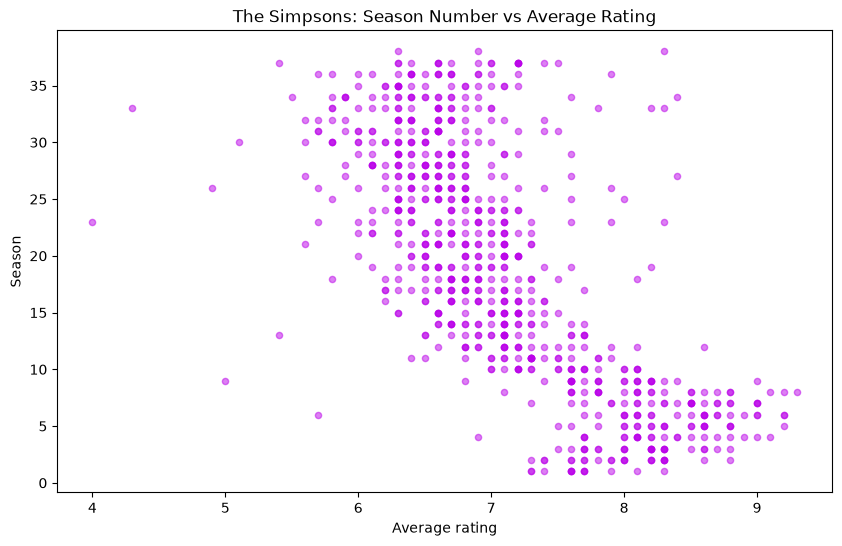

In [21]:
# The season numbers are stored as text, so they are converted to numbers before plotting
simpsons_ratings["seasonNumber"] = pd.to_numeric(simpsons_ratings["seasonNumber"])

# Create an empty figure (10 x 6 inches) and a plot area to draw on
fig, ax = plt.subplots(figsize=(10, 6))

# White background for both the figure and the plot area
fig.patch.set_facecolor("white")
ax.set_facecolor("white")

# Purple (#BB03E9) semi-transparent dots: one dot for each episode
simpsons_ratings.plot.scatter(
    x="averageRating",
    y="seasonNumber",
    color="#BB03E9",
    alpha=0.5,
    ax=ax
)

# Black title, axis labels, ticks and frame so that everything is readable on the white background
ax.set_title("The Simpsons: Season Number vs Average Rating", color="black")
ax.set_xlabel("Average rating", color="black")
ax.set_ylabel("Season", color="black")
ax.tick_params(colors="black")
for spine in ax.spines.values():
    spine.set_color("black")

# Display the plot
plt.show()

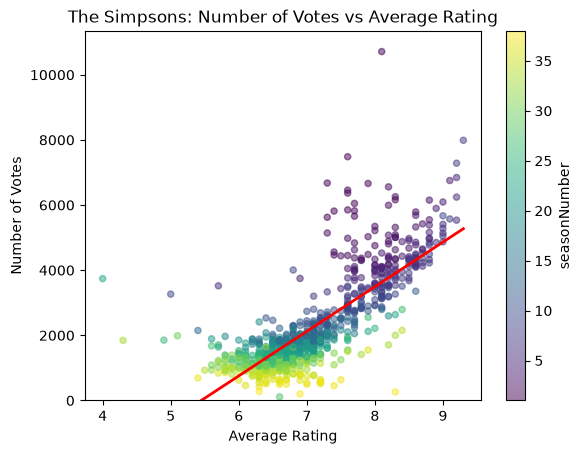

In [22]:
# numpy is used for the calculations of the trend line
import numpy as np

# Scatterplot of number of votes vs average rating, with the dots colored by season number
# (the viridis color scale goes from purple for early seasons to yellow for late seasons)
ax = simpsons_ratings.plot.scatter(
    x="averageRating",
    y="numVotes",
    c="seasonNumber",
    colormap="viridis",
    alpha=0.5
)

# Fit the trend line (drop rows with missing values first, because the fit cannot handle them)
# polyfit(..., 1) fits a straight line and returns its slope and intercept
data = simpsons_ratings[["averageRating", "numVotes"]].dropna()
slope, intercept = np.polyfit(data["averageRating"], data["numVotes"], 1)

# Draw the line across the whole range of ratings: 100 evenly spaced x values from the lowest to the highest rating,
# and the y value of the line (slope * x + intercept) for each of them
x = np.linspace(data["averageRating"].min(), data["averageRating"].max(), 100)
ax.plot(x, slope * x + intercept, color="red", linewidth=2)

# Title and axis labels
plt.title("The Simpsons: Number of Votes vs Average Rating")
plt.xlabel("Average Rating")
plt.ylabel("Number of Votes")

# Start the y axis from zero, so the number of votes is not exaggerated
plt.ylim(bottom=0)

# Display the plot
plt.show()

## K-means cluster analysis

Cluster analysis groups episodes that are similar to each other. K-means does this by dividing the episodes into a chosen number of groups (`k`), so that the episodes in the same group are as close to each other as possible. The episodes are compared using three variables: number of votes, average rating and season number.

Some preparation is needed before the clustering:

- **One row per episode** - duplicate episode titles are removed and rows with missing values are dropped.
- **Logarithm of the votes** - the number of votes is very skewed (a few episodes have many more votes than the rest), so its logarithm is used.
- **Standardizing** - the variables have very different scales (votes in the thousands, ratings between 1 and 10), so all of them are rescaled to have a mean of 0 and a standard deviation of 1. This way each variable has the same weight in the clustering.

To decide how many clusters to use, k-means is run with 2 to 8 clusters and the **silhouette score** is calculated for each. The score shows how well the episodes fit their own cluster compared with the other clusters. It is between -1 and 1, and a higher value means better separated clusters.

In [23]:
# Install scikit-learn, the library that contains k-means (the installation is skipped if it is already installed)
pip install scikit-learn


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [26]:
# The tools needed for the clustering:
# StandardScaler rescales the variables, KMeans does the clustering and silhouette_score measures how good the clusters are
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# numpy and matplotlib were already imported above, they are repeated here so that this cell also works on its own
import numpy as np
import matplotlib.pyplot as plt

# 1. One row per episode, only the columns needed, no missing values
#    - features are the three variables used to group the episodes
#    - drop_duplicates keeps only the first row of each episode title, so that no episode is counted twice
#    - dropna removes the rows where any of the three variables is missing
#    - copy makes an independent table, so that the original table is not changed later
features = ["numVotes", "averageRating", "seasonNumber"]
episodes = (
    simpsons_ratings
    .drop_duplicates(subset="episode_title")   # episode_title identifies each episode
    .dropna(subset=features)
    .copy()
)

# 2. numVotes is very skewed, so use its log
#    (the logarithm makes the difference between a few very popular episodes and the rest smaller)
X = episodes[features].copy()
X["numVotes"] = np.log10(X["numVotes"])

# 3. Standardize so all features count equally
#    (each variable is rescaled to a mean of 0 and a standard deviation of 1)
X_scaled = StandardScaler().fit_transform(X)

# 4. Choose the number of clusters
#    Run k-means with 2 to 8 clusters and print the silhouette score for each (a higher score is better).
#    n_init=10 repeats the clustering 10 times with different starting points and keeps the best result,
#    and random_state=42 makes the result the same every time the code is run.
for k in range(2, 9):
    labels = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X_scaled)
    print(k, round(silhouette_score(X_scaled, labels), 3))

2 0.537
3 0.464
4 0.398
5 0.354
6 0.34
7 0.316
8 0.334


## Choosing 3 clusters

The silhouette scores above are highest for 2 clusters, but the scatterplots suggested that the episodes can be divided into more than two groups. Three clusters still have a reasonably good score and give a more detailed division of the episodes, so 3 clusters are used in the subsequent analysis.

The final model is fitted with 3 clusters, and each episode gets a cluster number (0, 1 or 2) in the new column `cluster`. The clusters are then described by the mean values of the three variables and by the number of episodes in each cluster. The cluster numbers are only labels and have no order, so the clusters should be interpreted by their mean values and not by their numbers.

In [27]:
# Fit the final k-means model with 3 clusters (the same settings as before)
# and save the cluster of each episode in a new column
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42) 
episodes["cluster"] = kmeans.fit_predict(X_scaled)

# Profile the clusters: what is typical for each group?
# The mean of each variable by cluster (the original, not the standardized, values)
print(episodes.groupby("cluster")[features].mean().round(2))

# The number of episodes in each cluster
print(episodes["cluster"].value_counts().sort_index())

         numVotes  averageRating  seasonNumber
cluster                                       
0         4253.74           8.15          5.94
1         1112.34           6.46         30.43
2         1939.46           6.96         17.27
cluster
0    222
1    290
2    298
Name: count, dtype: int64


## Plotting the 3 clusters

A scatterplot of average rating and season number, with a different color for each cluster, shows how the clusters divide the seasons of the series. Each cluster is drawn separately, so that it gets its own color and its own entry in the legend. The plot has a dark grey background with white text.

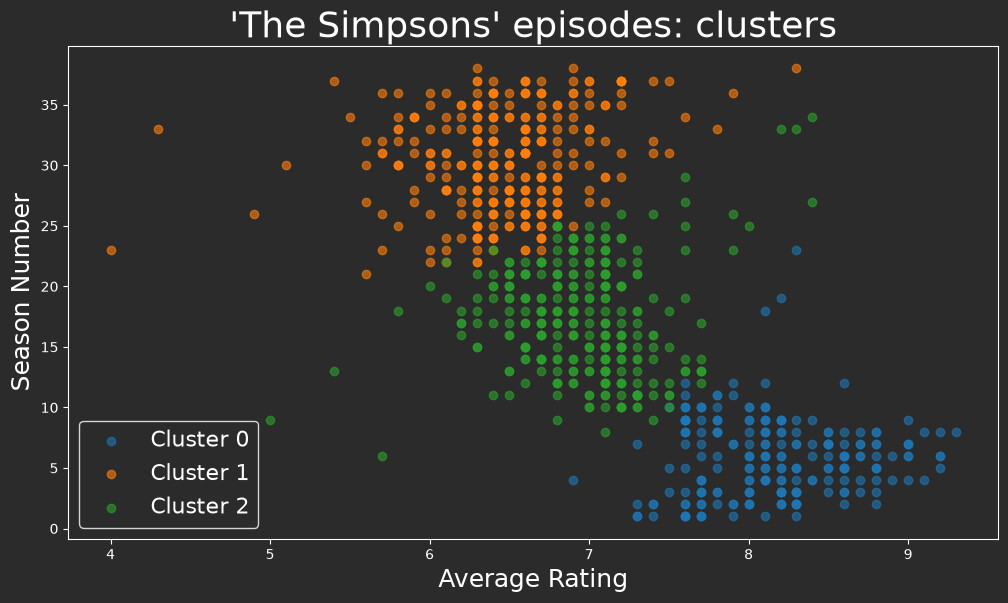

In [28]:
# Create a wide figure (12 x 6.4 inches, close to 16:9) and a plot area to draw on
fig, ax = plt.subplots(figsize=(12, 6.4))   # 16:9

# Dark grey background for both the figure and the plot area
fig.patch.set_facecolor("#2B2B2B")
ax.set_facecolor("#2B2B2B")

# Draw each cluster separately, so that every cluster gets its own color and legend entry
for cluster in sorted(episodes["cluster"].unique()):
    subset = episodes[episodes["cluster"] == cluster]
    ax.scatter(
        subset["averageRating"], subset["seasonNumber"],
        label=f"Cluster {cluster}", alpha=0.6
    )

# White text, ticks and frame, so that everything is readable on the dark background
ax.set_xlabel("Average Rating", color="white", fontsize=18)
ax.set_ylabel("Season Number", color="white", fontsize=18)
ax.set_title("'The Simpsons' episodes: clusters", color="white", fontsize=26)
ax.tick_params(colors="white")
for spine in ax.spines.values():
    spine.set_color("white")

# Legend with dark background and white text
legend = ax.legend(facecolor="#2B2B2B", edgecolor="white", fontsize=16)
legend.get_title().set_color("white")
for text in legend.get_texts():
    text.set_color("white")

# Display the plot
plt.show()